### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DVFM = data.copy()
DVFM = DVFM[DVFM['category']=='vegetables and fruits']
DVFM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448
5,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,484.85,0.2724
8,1/15/2008,Magway,Magway,Magway,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,181.82,0.1021
13,1/15/2008,Magway,Pakokku,Pakhangyi,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,242.42,0.1362
48,1/15/2008,Shan (North),Hopang,Kaung Ming Sang,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,1190.58,0.6689


In [12]:
DVFM = DVFM[['date', 'price']]
DVFM['date'] = pd.to_datetime(DVFM['date'])
mask = (DVFM['date']>=obv_st_date) & (DVFM['date']<=obv_end_date)
DVFM = DVFM.loc[mask]
DVFM = DVFM.set_index('date')
DVFM.head()

,price
date,
2008-01-15,969.70
2008-01-15,484.85
2008-01-15,181.82
2008-01-15,242.42
2008-01-15,1190.58


In [13]:
DVFM = DVFM.resample('MS').mean()
DVFM.head()

,price
date,
2008-01-01,859.156923
2008-02-01,795.805385
2008-03-01,848.876923
2008-04-01,694.560000
2008-05-01,767.373333


In [14]:
DVFM.shape

(169, 1)

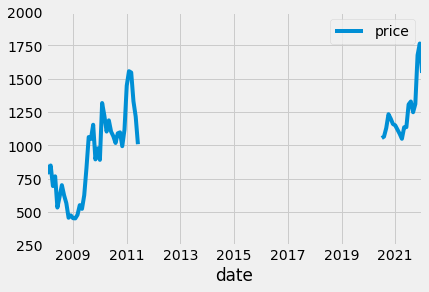

In [15]:
DVFM.plot(grid=True)
plt.show()

There is missing data.

In [16]:
obv_st_date = pd.to_datetime("2020-09-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2020-09-01")
pred_end_date = pd.to_datetime("2023-01-01")

In [17]:
mask = (DVFM.index>=obv_st_date) & (DVFM.index<=obv_end_date)
DVFM = DVFM.loc[mask]
DVFM.head()

,price
date,
2020-09-01,1129.682556
2020-10-01,1233.438971
2020-11-01,1199.803709
2020-12-01,1159.349206
2021-01-01,1150.294964


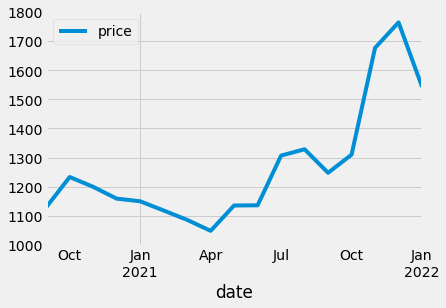

In [18]:
DVFM = DVFM.dropna()
DVFM.plot(grid=True)
plt.show()

There is a trend like `log`

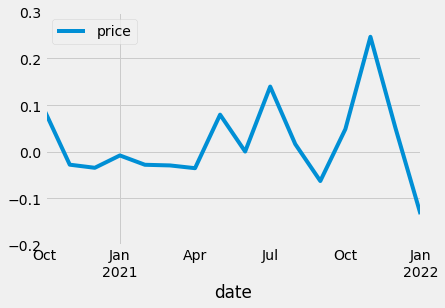

In [19]:
DVFM_diff_log = np.log(DVFM).diff().dropna()
DVFM_diff_log.plot(grid=True)
plt.show()

##### Checking Random Walk

In [20]:
RW_DVFM= adfuller(DVFM_diff_log)
RW_DVFM[1] # print P-value. If p-value<5%, reject null hypothesis

0.003843883923153202

##### Plotting ACF and PACF

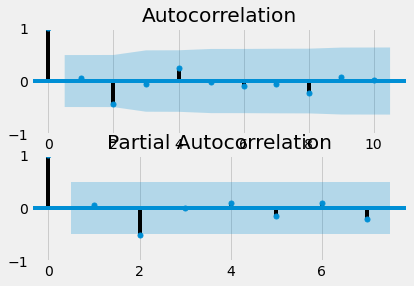

In [21]:
fig, axes=plt.subplots(2,1)
plot_acf(DVFM_diff_log, lags=10, ax=axes[0])
plot_pacf(DVFM_diff_log, lags=7, ax=axes[1])
plt.show()

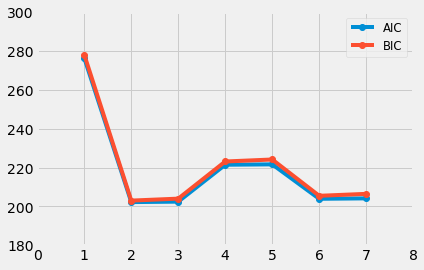

In [22]:
AIC, BIC = AIC_BIC_withOrderRange(DVFM, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [23]:
AIC, BIC

(array([293.63116046, 276.30039104, 202.22320173, 202.45692053,
        221.44162486, 221.63781777, 203.91887392, 204.14402191]),
 array([294.46437381, 277.96681772, 202.99579045, 204.00209798,
        223.10805155, 224.1374578 , 205.46405136, 206.46178807]))

We will run again 2:(0,1,0), 3:(0,1,1), 6:(1,1,0), 7:(1,1,1)

In [24]:
mod_orders = [
    (0,1,0),
    (0,1,1),
    (1,1,0),
    (1,1,1)
]

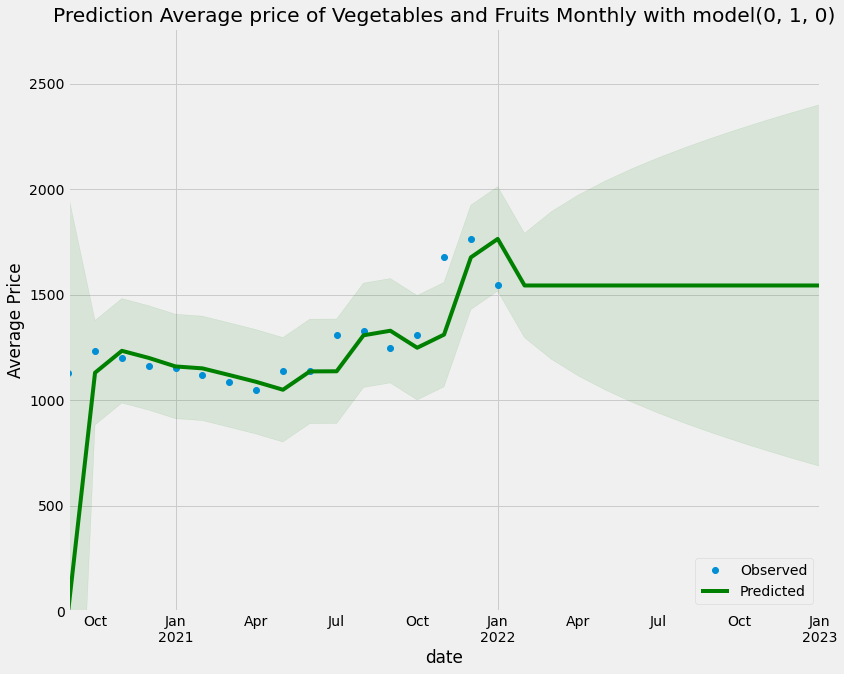

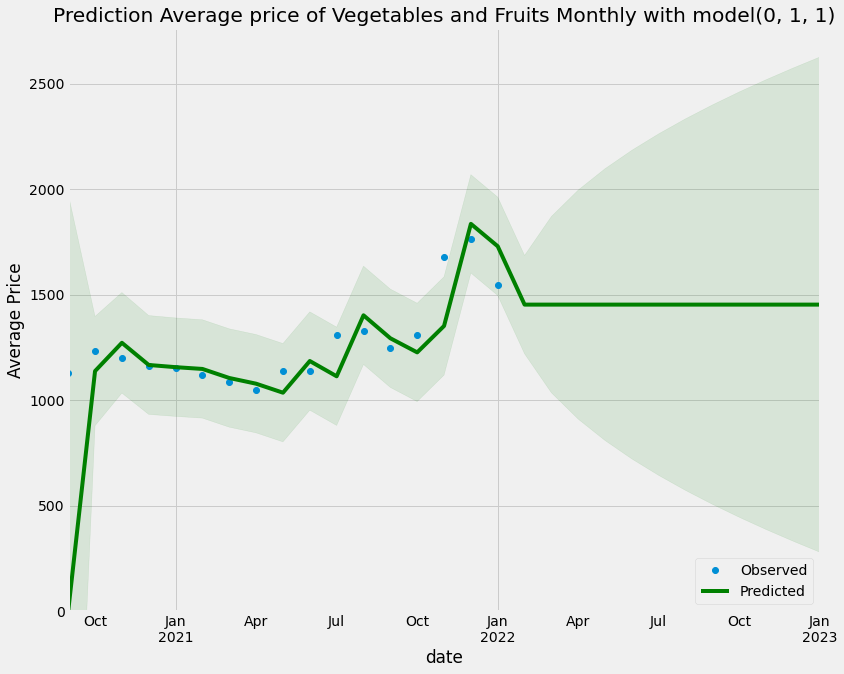

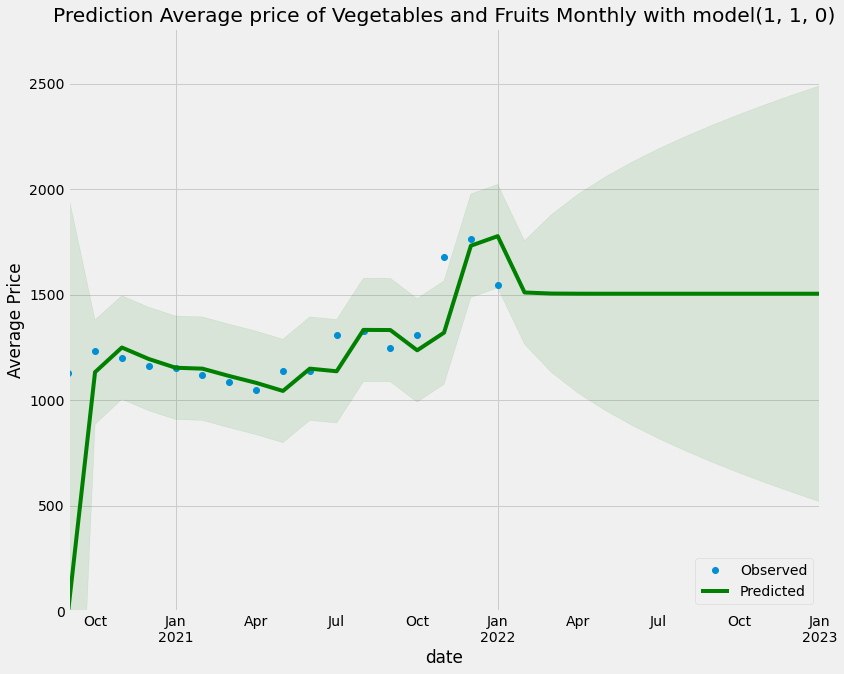

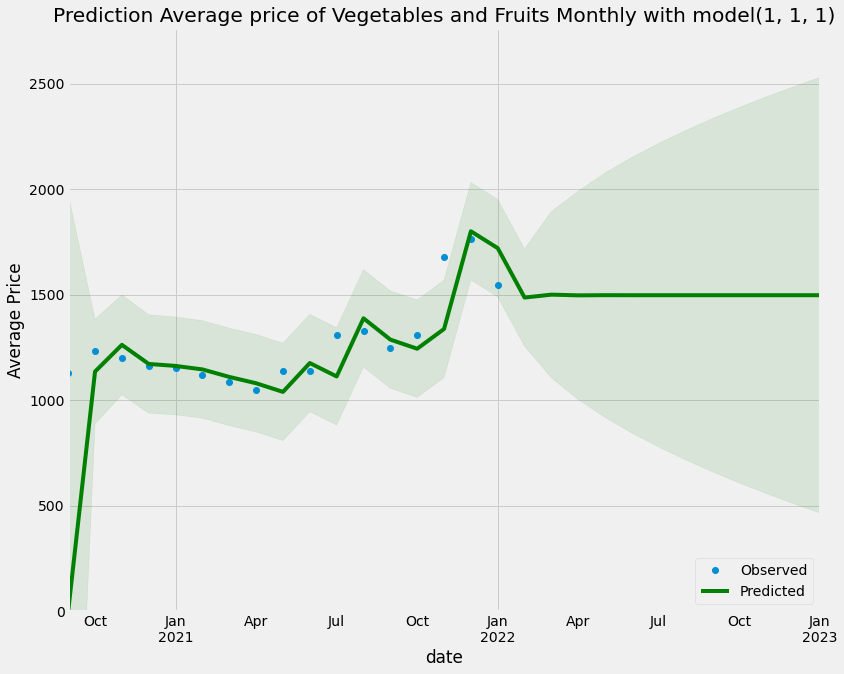

In [25]:
DVFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DVFM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Vegetables and Fruits Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DVFM_models.append(model)

Now we choose (0,1,0)

In [26]:
DVFM_model = DVFM_models[0]

In [27]:
DVFM_pred = DVFM_model.predict(pred_st_date, pred_end_date)
DVFM_pred

2020-09-01       0.000000
2020-10-01    1129.682556
2020-11-01    1233.438971
2020-12-01    1199.803709
2021-01-01    1159.349206
2021-02-01    1150.294964
2021-03-01    1118.714286
2021-04-01    1086.479403
2021-05-01    1048.954155
2021-06-01    1135.825817
2021-07-01    1136.453374
2021-08-01    1306.917722
2021-09-01    1328.623141
2021-10-01    1247.974311
2021-11-01    1310.143678
2021-12-01    1676.353356
2022-01-01    1763.669808
2022-02-01    1543.057325
2022-03-01    1543.057325
2022-04-01    1543.057325
2022-05-01    1543.057325
2022-06-01    1543.057325
2022-07-01    1543.057325
2022-08-01    1543.057325
2022-09-01    1543.057325
2022-10-01    1543.057325
2022-11-01    1543.057325
2022-12-01    1543.057325
2023-01-01    1543.057325
Freq: MS, Name: predicted_mean, dtype: float64